# 01 — Primeira demonstração: RailPulse com dados reais de F3

In [3]:
from pathlib import Path
import os, sys, zipfile, subprocess
BASE = Path.cwd()
if not (BASE / 'iot_monitor').exists():
    git_repo = "https://github.com/jorgek14/railpulse-metropt3.git"
    if git_repo.strip():
        subprocess.run(['git', 'clone', git_repo, '/content/railpulse-metropt3'], check=True)
        BASE = Path('/content/railpulse-metropt3')
    else:
        try:
            from google.colab import files
        except ImportError as e:
            raise RuntimeError('Abra o notebook na raiz do repositório ou no Colab e envie o ZIP do projeto.') from e
        print('Selecione o ZIP do repositório RailPulse. NÃO selecione o CSV original agora.')
        enviados = files.upload()
        nome = next((n for n in enviados if n.endswith('.zip')), None)
        assert nome, 'É necessário carregar o ZIP do projeto.'
        BASE = Path('/content/railpulse-metropt3')
        BASE.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(nome) as z:
            z.extractall(BASE)
os.chdir(BASE)
sys.path.insert(0, str(BASE))
print('Raiz do projeto:', BASE)

Raiz do projeto: /content/railpulse-metropt3


## 1. Veja as medições reais de pressão e corrente

Leituras do recorte: 303


,timestamp,TP3,Motor_current,Oil_temperature,DV_eletric
0,2020-06-05 09:30:00,8.074,0.0425,58.875,0.0
1,2020-06-05 09:30:10,8.062,5.1775,58.800,1.0
2,2020-06-05 09:30:20,8.192,5.8775,58.700,1.0
3,2020-06-05 09:30:30,8.442,5.8075,58.825,1.0
4,2020-06-05 09:30:40,8.536,5.8125,59.550,1.0


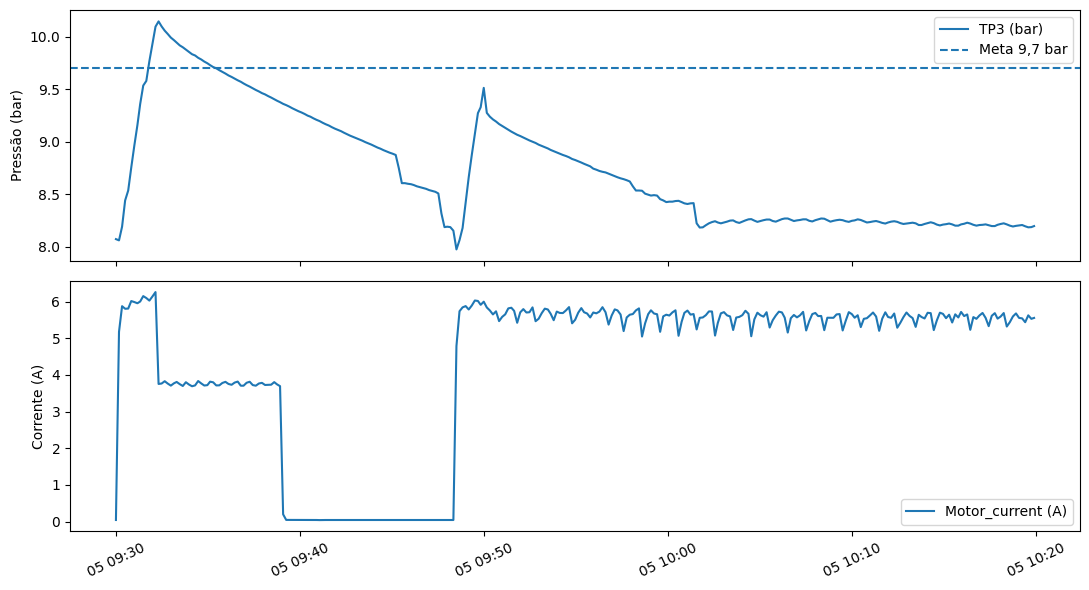

In [4]:
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

amostras=pd.read_csv(BASE/'dados_demo/demo_f3.csv',parse_dates=['timestamp'])
print('Leituras do recorte:',len(amostras))
display(amostras[['timestamp','TP3','Motor_current','Oil_temperature','DV_eletric']].head())
fig,axs=plt.subplots(2,1,figsize=(11,6),sharex=True)
axs[0].plot(amostras.timestamp,amostras.TP3,label='TP3 (bar)');axs[0].axhline(9.7,ls='--',label='Meta 9,7 bar');axs[0].set_ylabel('Pressão (bar)');axs[0].legend()
axs[1].plot(amostras.timestamp,amostras.Motor_current,label='Motor_current (A)');axs[1].set_ylabel('Corrente (A)');axs[1].legend();plt.xticks(rotation=25);plt.tight_layout();plt.show()

## 2. Envie as leituras ao detector amostra a amostra

In [5]:
import json
from iot_monitor.detector import Detector
parametros=json.loads((BASE/'parametros_etapa4.json').read_text())
print('Pressão de referência:',parametros['pressao_referencia_bar'],'bar')
print('Percentil P99 de recuperação:',parametros['q99_tempo_ate_9_7_s'],'s')
detector=Detector(parametros)
alertas=[]
for r in amostras.to_dict(orient='records'):
    r['timestamp']=str(r['timestamp'])
    alertas.extend(detector.process(r))
print('Alertas detectados no recorte:',len(alertas))
display(pd.DataFrame(alertas)[['timestamp','method','pressure_bar','elapsed_s']])
assert len(alertas)==3
assert any(a['method']=='Pressao_nao_recuperada_q99' and a['timestamp']=='2020-06-05 09:51:38' for a in alertas)
print('✅ Regra principal identificada no instante esperado (09:51:38).')

Pressão de referência: 9.7 bar
Percentil P99 de recuperação: 188.0 s
Alertas detectados no recorte: 3


,timestamp,method,pressure_bar,elapsed_s
0,2020-06-05 09:51:38,Pressao_nao_recuperada_q99,9.082,188.0
1,2020-06-05 09:51:38,Somente_carga_mesmo_limiar,9.082,188.0
2,2020-06-05 09:54:17,Carga_longa_q99,8.874,347.0


✅ Regra principal identificada no instante esperado (09:51:38).


## 3. Resultado

O algoritmo sinaliza o ciclo de carga que ultrapassa 188 segundos sem alcançar 9,7 bar. No recorte F3 isso ocorre antes das 10h, que é o horário documentado, não necessariamente o início real da avaria. O resultado não prova capacidade de previsão prospectiva.